# Exploratory Data Analysis (EDA) on Retail Sales Data

**Objective:** Explore retail transactions to understand sales trends, customer demographics, and product/category performance, then provide actionable business recommendations.

**Tools:** Python, pandas, Matplotlib, Seaborn, Jupyter Notebook.

> **Dataset note:** This notebook is designed for the common Kaggle Retail Sales Dataset with columns such as `Date`, `Gender`, `Age`, `Product Category`, `Quantity`, `Price per Unit`, and `Total Amount`. If your dataset uses different column names, update the column mapping in the next section. Some versions contain categories but not individual product names; in that case, the notebook analyzes categories rather than claiming to identify individual products.

## 1. Import libraries

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 2. Load the dataset

Place your CSV file at `data/retail_sales.csv` in the repository. If you're running this in Google Colab, you can upload the file when prompted.

In [40]:
csv_path = Path("../data/retail_sales.csv")

if not csv_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_path = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            "Could not find ../data/retail_sales.csv. Place your CSV in the data folder "
            "or run this notebook in Google Colab and upload it."
        )

df = pd.read_csv(csv_path)
print("Dataset loaded successfully.")
df.head()

Saving retail_sales_dataset.csv to retail_sales_dataset (4).csv
Dataset loaded successfully.


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [41]:

import pandas as pd

url = "https://raw.githubusercontent.com/navya543s/OIBSIP/main/retail_sales_dataset.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [42]:

# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. Check column names and data types
print("\nDataset information:")
df.info()

# 3. Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 4. Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 5. View summary statistics
print("\nDescriptive statistics:")
display(df.describe())

# 6. Check unique values in categorical columns
print("\nProduct categories:")
print(df["Product Category"].unique())

print("\nGender values:")
print(df["Gender"].unique())


Dataset shape: (1000, 9)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Missing values in each column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Number of duplicate rows: 0

Descriptive statis

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,"1,000.00","1,000.00","1,000.00","1,000.00","1,000.00"
mean,500.50,41.39,2.51,179.89,456.00
std,288.82,13.68,1.13,189.68,560.00
min,1.00,18.00,1.00,25.00,25.00
25%,250.75,29.00,1.00,30.00,60.00
50%,500.50,42.00,3.00,50.00,135.00
75%,750.25,53.00,4.00,300.00,900.00
max,"1,000.00",64.00,4.00,500.00,"2,000.00"



Product categories:
['Beauty' 'Clothing' 'Electronics']

Gender values:
['Male' 'Female']


In [43]:

# Calculate mean, median, mode, and standard deviation
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    print(f"\nColumn: {col}")
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode().tolist())
    print("Standard deviation:", df[col].std())



Column: Transaction ID
Mean: 500.5
Median: 500.5
Mode: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 2

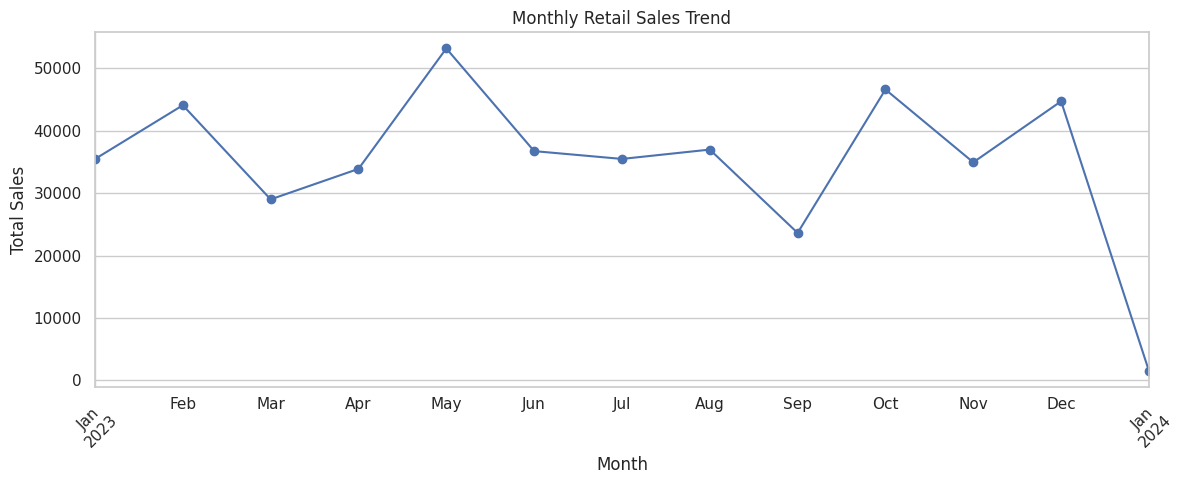

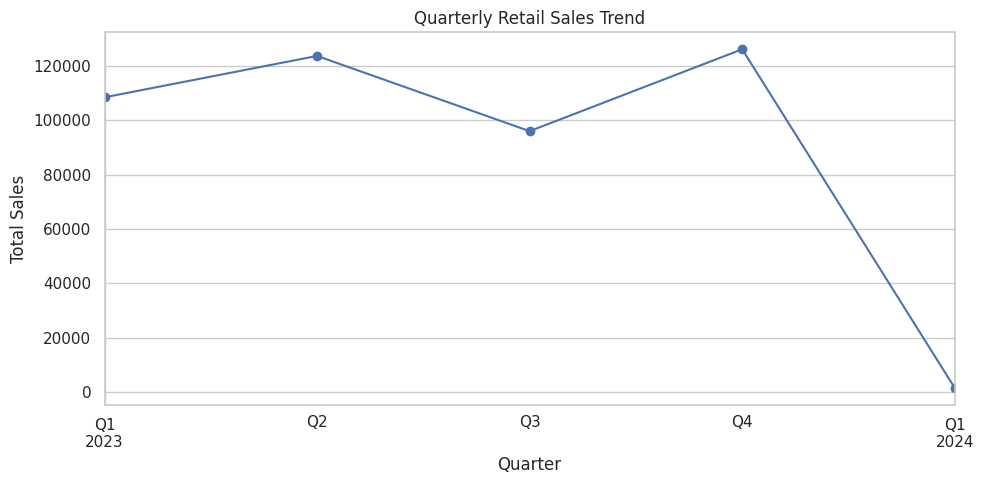

Highest sales month: 2023-05
Lowest sales month: 2024-01
Highest sales quarter: 2023Q4
Lowest sales quarter: 2024Q1


In [44]:

import pandas as pd
import matplotlib.pyplot as plt

# Convert the Date column into a proper date format
df["Date"] = pd.to_datetime(df["Date"])

# Create month and quarter columns
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

# Calculate total sales for each month
monthly_sales = df.groupby("Month")["Total Amount"].sum()

# Calculate total sales for each quarter
quarterly_sales = df.groupby("Quarter")["Total Amount"].sum()

# Monthly sales line chart
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Quarterly sales line chart
plt.figure(figsize=(10, 5))
quarterly_sales.plot(kind="line", marker="o")
plt.title("Quarterly Retail Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Highest sales month:", monthly_sales.idxmax())
print("Lowest sales month:", monthly_sales.idxmin())
print("Highest sales quarter:", quarterly_sales.idxmax())
print("Lowest sales quarter:", quarterly_sales.idxmin())


### Monthly and Quarterly Sales Analysis

The monthly sales trend shows fluctuations throughout the year, with the highest sales occurring around May 2023. Sales declined considerably in September before recovering in October. The final plotted month, January 2024, has unusually low sales and requires further investigation.

The quarterly sales chart shows variations in revenue across quarters. Before making business decisions, the final period should be checked for incomplete data.

**Business implication:** Monitor monthly sales performance, investigate periods of declining revenue, and compare equivalent periods before making seasonal inventory or promotional decisions.


In [45]:

# Check the date range in the dataset
print("First transaction date:", df["Date"].min())
print("Last transaction date:", df["Date"].max())

# Count transactions in each month
monthly_transactions = df.groupby(
    df["Date"].dt.to_period("M")
).size()

print("\nTransactions per month:")
print(monthly_transactions)

# Check the quarterly transaction counts
quarterly_transactions = df.groupby(
    df["Date"].dt.to_period("Q")
).size()

print("\nTransactions per quarter:")
print(quarterly_transactions)


First transaction date: 2023-01-01 00:00:00
Last transaction date: 2024-01-01 00:00:00

Transactions per month:
Date
2023-01     76
2023-02     85
2023-03     73
2023-04     86
2023-05    105
2023-06     77
2023-07     72
2023-08     94
2023-09     65
2023-10     96
2023-11     78
2023-12     91
2024-01      2
Freq: M, dtype: int64

Transactions per quarter:
Date
2023Q1    234
2023Q2    268
2023Q3    231
2023Q4    265
2024Q1      2
Freq: Q-DEC, dtype: int64


### Data Quality and Time-Series Observation

The dataset contains 1,000 transactions spanning January 2023 to January 2024. May 2023 recorded the highest monthly transaction count, with 105 transactions. January 2024 contained only two transactions, which suggests that the final month may be incomplete.

The unusually low transaction count in January 2024 affects both the monthly and quarterly sales trends. Therefore, this period should be treated cautiously when comparing performance across months or quarters.

**Limitation:** The dataset does not contain a complete January 2024 reporting period, so conclusions about the final month's sales performance may be unreliable.

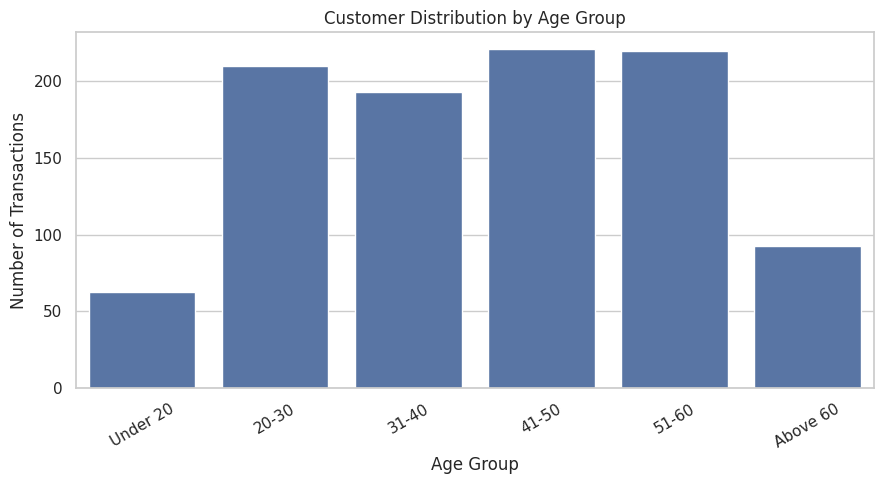

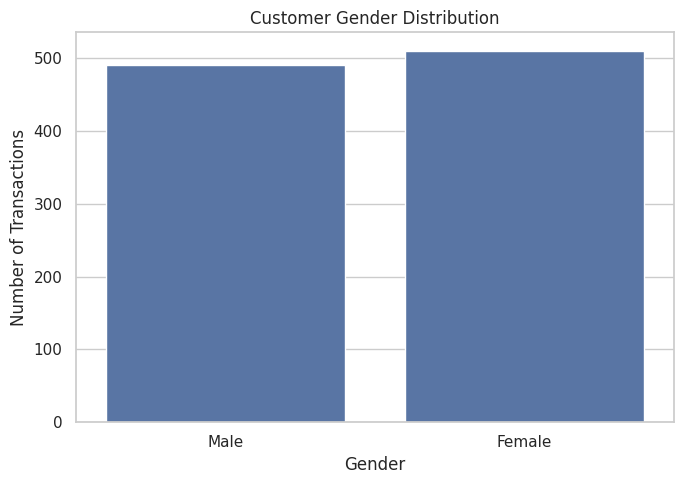

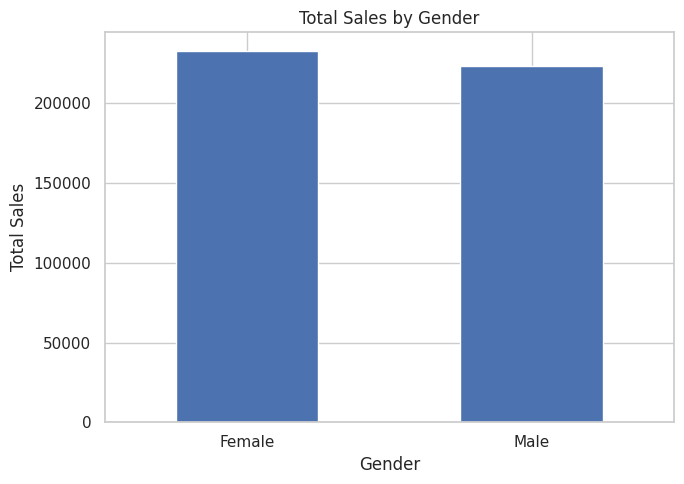

Transactions by age group:
Age Group
Under 20     63
20-30       210
31-40       193
41-50       221
51-60       220
Above 60     93
Name: count, dtype: int64

Total sales by gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


In [46]:

import matplotlib.pyplot as plt
import seaborn as sns

# Create age groups
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=["Under 20", "20-30", "31-40", "41-50", "51-60", "Above 60"]
)

# Chart 1: Number of customers by age group
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Age Group")
plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Chart 2: Gender distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Gender")
plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

# Chart 3: Revenue by gender
gender_sales = df.groupby("Gender", observed=True)["Total Amount"].sum()

gender_sales.plot(kind="bar", figsize=(7, 5))
plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Transactions by age group:")
print(df["Age Group"].value_counts().sort_index())

print("\nTotal sales by gender:")
print(gender_sales)


### Customer Demographics Analysis

**Age-group analysis:** The 41–50 age group recorded the highest number of transactions (221), followed closely by the 51–60 age group (220). Customers aged 20–30 contributed 210 transactions. Customers under 20 recorded the fewest transactions (63).

**Gender analysis:** Female customers generated slightly higher total sales than male customers in this dataset. The difference should be evaluated alongside transaction counts and average transaction values.

**Business insight:** The business could test targeted promotions for the 41–60 age groups while exploring ways to increase engagement among younger customers. These strategies should be evaluated using actual campaign results rather than assuming that demographic differences imply purchasing preferences.

Revenue by Product Category:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


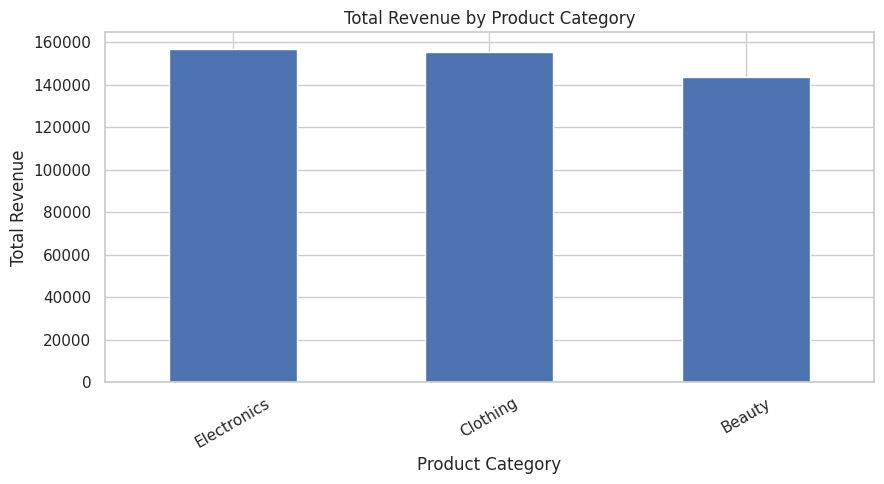


No individual Product column exists.
This dataset supports category-level analysis, not individual product rankings.


In [47]:

# Total revenue by product category
category_sales = df.groupby(
    "Product Category"
)["Total Amount"].sum().sort_values(ascending=False)

print("Revenue by Product Category:")
print(category_sales)

# Chart: Revenue by category
plt.figure(figsize=(9, 5))
category_sales.plot(kind="bar")
plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Top 10 best-selling products, if product names are available
if "Product" in df.columns:
    top_products = df.groupby("Product")["Quantity"].sum().sort_values(
        ascending=False
    ).head(10)

    print("\nTop 10 Products by Quantity Sold:")
    print(top_products)

    top_products.sort_values().plot(kind="barh", figsize=(9, 5))
    plt.title("Top 10 Best-Selling Products")
    plt.xlabel("Quantity Sold")
    plt.tight_layout()
    plt.show()
else:
    print("\nNo individual Product column exists.")
    print("This dataset supports category-level analysis, not individual product rankings.")


### Product Category Analysis

Electronics generated the highest total revenue at 156,905, followed closely by Clothing at 155,580. Beauty generated 143,515 in revenue.

The small difference between Electronics and Clothing suggests that both categories are important contributors to overall sales. Beauty generated less revenue than the other two categories.

**Business insight:** Maintain suitable inventory levels for Electronics and Clothing because of their strong revenue contributions. Investigate opportunities to improve Beauty category performance through customer feedback, product assortment reviews, and carefully measured promotional campaigns.

**Data limitation:** The dataset contains product categories but no individual product names. Therefore, the top 10 individual best-selling products cannot be identified from the available data.

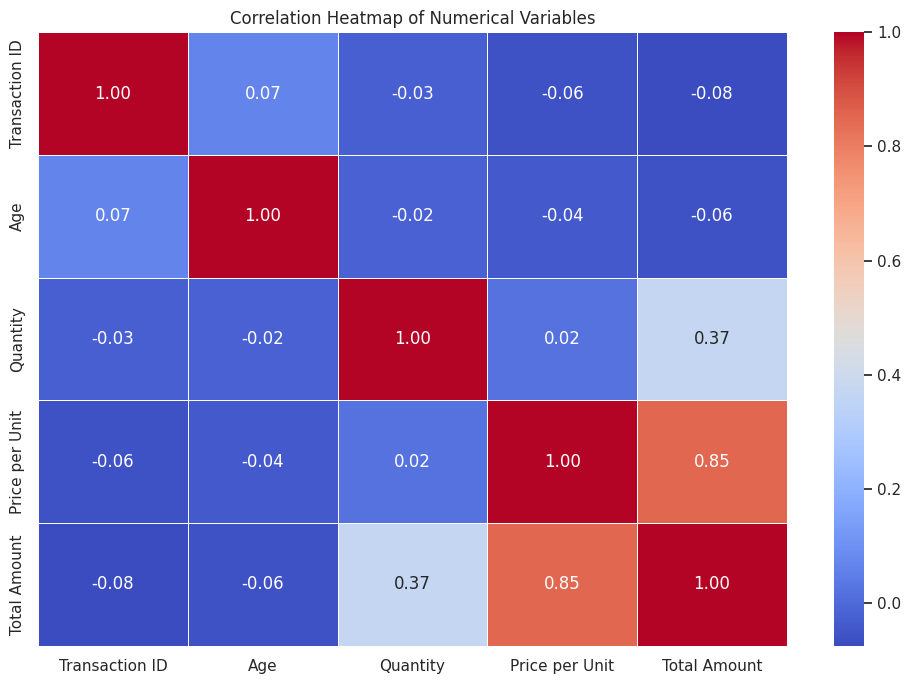

In [48]:

# Select numerical columns for correlation analysis
numeric_data = df.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numeric_data.corr()

# Draw the heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


### Correlation Analysis

The correlation heatmap shows a strong positive relationship between Price per Unit and Total Amount (0.85). Quantity and Total Amount have a moderate positive correlation (0.37). Age has very weak linear correlations with both Quantity (-0.02) and Total Amount (-0.06).

The relationship between Price per Unit and Total Amount is partly expected because transaction amount is calculated using quantity and unit price. Correlation alone does not establish causation.

**Business insight:** Consider quantity-based offers and product bundles to encourage larger purchases, then evaluate their impact on average transaction value. Customer age alone does not appear to be a strong linear indicator of transaction amount in this dataset.

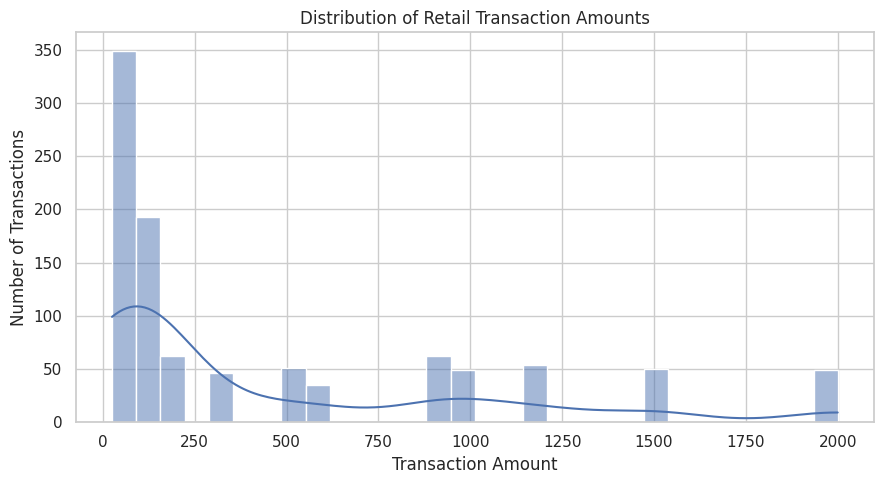

Median transaction amount: 135.0
Average transaction amount: 456.0
Maximum transaction amount: 2000


In [49]:

# Additional visualization: Distribution of transaction amounts

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Total Amount",
    bins=30,
    kde=True
)

plt.title("Distribution of Retail Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

# Calculate useful summary values
print("Median transaction amount:", df["Total Amount"].median())
print("Average transaction amount:", df["Total Amount"].mean())
print("Maximum transaction amount:", df["Total Amount"].max())


### Transaction Amount Distribution Analysis

The transaction amount distribution is positively skewed, with many transactions concentrated at lower amounts and fewer transactions at higher amounts. The median transaction amount is 135, while the mean is 456. The maximum transaction amount is 2,000.

The difference between the mean and median suggests that high-value transactions influence the average. Therefore, the median may provide a more representative measure of a typical transaction than the mean.

**Business insight:** Evaluate strategies that encourage customers to make larger purchases, such as product bundles and targeted offers. Monitor both the average and median transaction amounts to determine whether these strategies improve typical customer spending.

## Final Business Recommendations

Based on the exploratory data analysis, the following actions are recommended:

**1. Strengthen Electronics and Clothing performance**

Electronics generated 156,905 in revenue, while Clothing generated 155,580. Maintain appropriate inventory levels in both categories, monitor demand, and test targeted promotions to improve revenue while protecting profit margins.

**2. Investigate low-revenue periods**

Monthly sales fluctuated during 2023, with a noticeable decline in September. Review transaction patterns, product availability, pricing, and promotional activity during lower-sales periods. January 2024 contains only two transactions, so it should not be compared directly with complete months.

**3. Encourage higher-value purchases**

The mean transaction amount (456) is substantially higher than the median (135). Test product bundles, complementary-product offers, and carefully designed minimum-spend promotions. Measure their impact on transaction value and profitability.

**4. Refine customer engagement**

Customers aged 41–50 recorded the highest transaction count (221), closely followed by ages 51–60 (220). Test relevant offers for these groups while exploring ways to engage younger customers. Evaluate campaign performance rather than assuming demographic patterns indicate customer preferences.

**5. Improve future analysis**

Collect individual product names and additional information such as discounts, costs, and profit margins. This would enable individual product rankings, more meaningful profitability analysis, and better-informed business decisions.

### Conclusion

The analysis identified differences in monthly sales, customer demographics, category revenue, and transaction values. Electronics and Clothing were the leading revenue categories, while transaction amounts were positively skewed. These findings can guide inventory planning, promotional testing, and further analysis. Conclusions should account for the incomplete January 2024 period and the limitations of the available dataset.

## 3. Standardize column names and inspect the data

In [50]:
# Normalize common naming differences while keeping readable column names.
df.columns = (
    df.columns.astype(str)
      .str.strip()
      .str.replace("_", " ", regex=False)
      .str.replace(r"\s+", " ", regex=True)
)

# Map common alternative column names to the names used in this notebook.
rename_map = {
    "Transaction ID": "Transaction ID",
    "Transaction.ID": "Transaction ID",
    "Customer ID": "Customer ID",
    "Customer.ID": "Customer ID",
    "Product Category": "Product Category",
    "Product.Category": "Product Category",
    "Price per Unit": "Price per Unit",
    "Price Per Unit": "Price per Unit",
    "Total Amount": "Total Amount",
    "Total.Amount": "Total Amount",
    "Order Date": "Date",
    "date": "Date",
}
df = df.rename(columns={c: rename_map[c] for c in df.columns if c in rename_map})

print("Rows and columns:", df.shape)
print("\nColumn names:", df.columns.tolist())
display(df.head())
display(df.info())
display(df.isnull().sum().to_frame("Missing values"))
print("Duplicate rows:", df.duplicated().sum())

Rows and columns: (1000, 12)

Column names: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount', 'Month', 'Quarter', 'Age Group']


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Month,Quarter,Age Group
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023-11,2023Q4,31-40
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023-02,2023Q1,20-30
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023-01,2023Q1,41-50
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023-05,2023Q2,31-40
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023-05,2023Q2,20-30


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[ns]
 2   Customer ID       1000 non-null   object        
 3   Gender            1000 non-null   object        
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   object        
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
 9   Month             1000 non-null   period[M]     
 10  Quarter           1000 non-null   period[Q-DEC] 
 11  Age Group         1000 non-null   category      
dtypes: category(1), datetime64[ns](1), int64(5), object(3), period[M](1), period[Q-DEC](1)
memory usage: 87.3+ KB


None

,Missing values
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0
Month,0


Duplicate rows: 0


## 4. Clean and prepare the data

In [51]:
# Convert date column if present.
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert expected numeric columns where present.
numeric_candidates = ["Age", "Quantity", "Price per Unit", "Total Amount"]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove exact duplicate rows.
before = len(df)
df = df.drop_duplicates().copy()
print(f"Removed {before - len(df)} duplicate rows.")

# Report missing values before deciding how to handle them.
print("Missing values after type conversion:")
display(df.isnull().sum().to_frame("Missing values"))

# Drop rows missing key analysis fields, only if those fields exist.
key_fields = [c for c in ["Date", "Total Amount", "Product Category", "Age", "Gender"] if c in df.columns]
if key_fields:
    before = len(df)
    df = df.dropna(subset=key_fields).copy()
    print(f"Removed {before - len(df)} rows missing key analysis fields.")

# Check whether sales amount matches quantity * unit price.
if all(c in df.columns for c in ["Quantity", "Price per Unit", "Total Amount"]):
    df["Calculated Amount"] = df["Quantity"] * df["Price per Unit"]
    df["Amount Difference"] = df["Total Amount"] - df["Calculated Amount"]
    print("Rows where Total Amount differs from Quantity × Price per Unit:",
          (df["Amount Difference"].abs() > 0.01).sum())

print("Cleaned dataset shape:", df.shape)

Removed 0 duplicate rows.
Missing values after type conversion:


,Missing values
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0
Month,0


Removed 0 rows missing key analysis fields.
Rows where Total Amount differs from Quantity × Price per Unit: 0
Cleaned dataset shape: (1000, 14)


## 5. Descriptive statistics

In [52]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
if num_cols:
    display(df[num_cols].agg(["count", "mean", "median", "std", "min", "max"]).T)
else:
    print("No numeric columns were detected.")

,count,mean,median,std,min,max
Transaction ID,"1,000.00",500.50,500.50,288.82,1.00,"1,000.00"
Age,"1,000.00",41.39,42.00,13.68,18.00,64.00
Quantity,"1,000.00",2.51,3.00,1.13,1.00,4.00
Price per Unit,"1,000.00",179.89,50.00,189.68,25.00,500.00
Total Amount,"1,000.00",456.00,135.00,560.00,25.00,"2,000.00"
Calculated Amount,"1,000.00",456.00,135.00,560.00,25.00,"2,000.00"
Amount Difference,"1,000.00",0.00,0.00,0.00,0.00,0.00


## 6. Monthly and quarterly sales trends

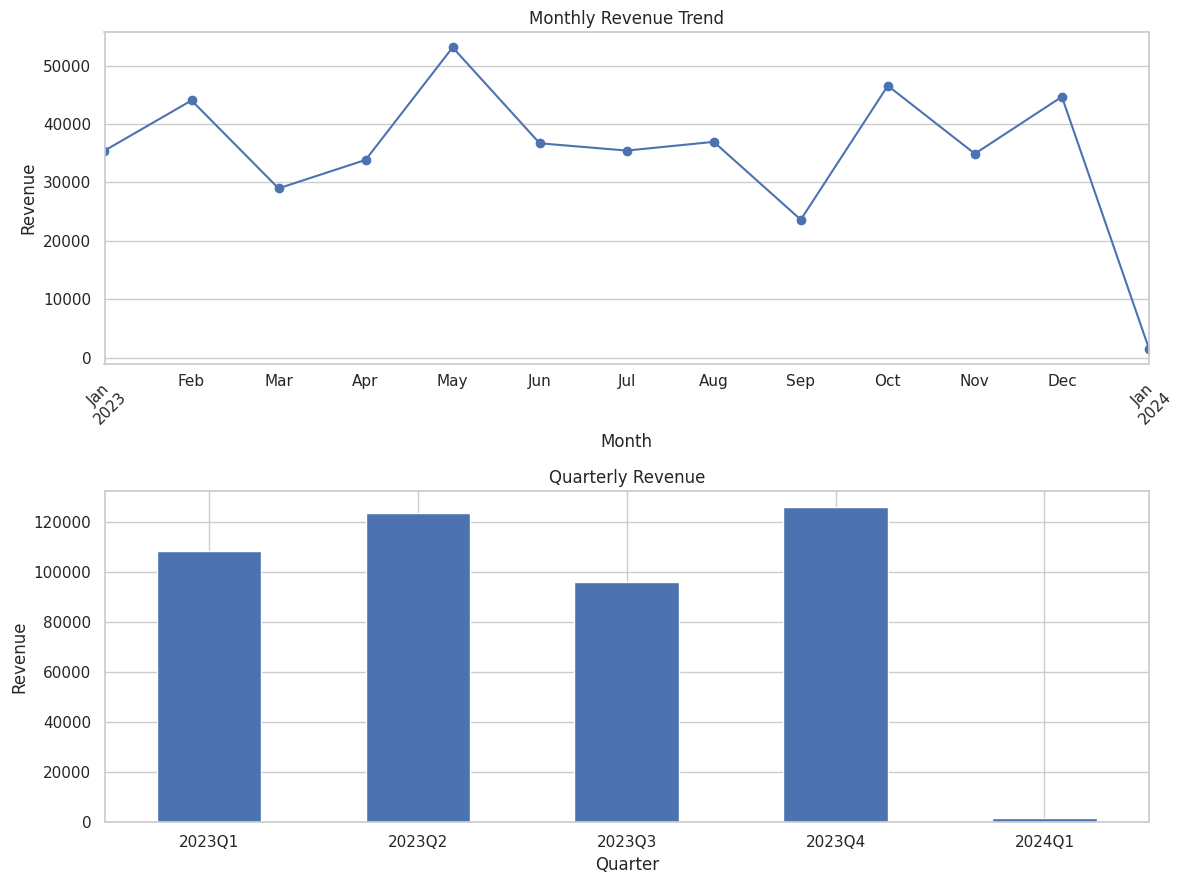

Highest-revenue month: 2023-05 with revenue 53150
Lowest-revenue month: 2024-01 with revenue 1530


In [53]:
if "Date" in df.columns and "Total Amount" in df.columns:
    dated = df.dropna(subset=["Date"]).copy()
    dated["Month"] = dated["Date"].dt.to_period("M").dt.to_timestamp()
    dated["Quarter"] = dated["Date"].dt.to_period("Q").astype(str)

    monthly_sales = dated.groupby("Month")["Total Amount"].sum().sort_index()
    quarterly_sales = dated.groupby("Quarter")["Total Amount"].sum()

    fig, axes = plt.subplots(2, 1, figsize=(12, 9))
    monthly_sales.plot(marker="o", ax=axes[0])
    axes[0].set_title("Monthly Revenue Trend")
    axes[0].set_xlabel("Month")
    axes[0].set_ylabel("Revenue")
    axes[0].tick_params(axis="x", rotation=45)

    quarterly_sales.plot(kind="bar", ax=axes[1])
    axes[1].set_title("Quarterly Revenue")
    axes[1].set_xlabel("Quarter")
    axes[1].set_ylabel("Revenue")
    axes[1].tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

    print("Highest-revenue month:", monthly_sales.idxmax().strftime("%Y-%m"),
          "with revenue", round(monthly_sales.max(), 2))
    print("Lowest-revenue month:", monthly_sales.idxmin().strftime("%Y-%m"),
          "with revenue", round(monthly_sales.min(), 2))
else:
    print("Date and/or Total Amount column is missing; update column names to run time-series analysis.")

**Observation prompt:** After viewing the charts, write 2–3 sentences here. Mention the strongest and weakest months/quarters and whether revenue appears stable, seasonal, or irregular. Base the observation on your actual chart, not assumptions.

## 7. Customer demographics: age groups and gender

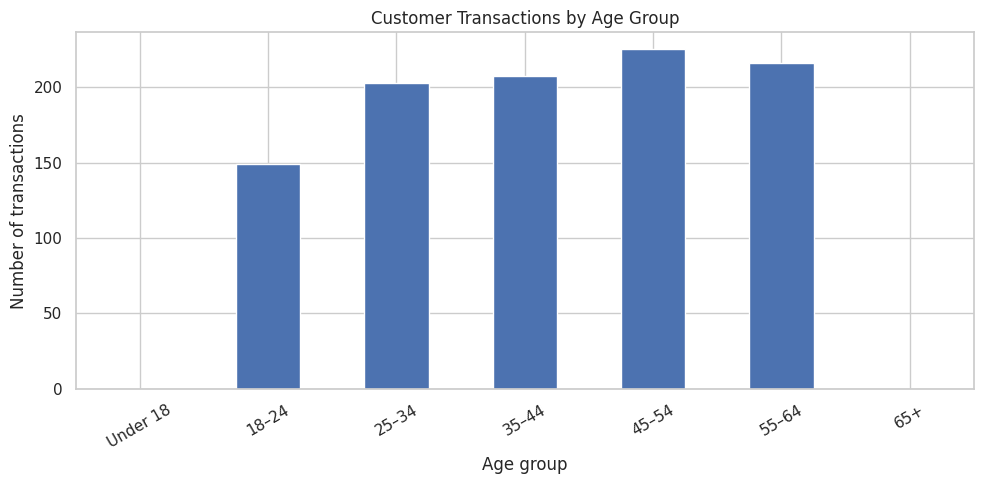

,Revenue by age group
Age Group,
45–54,97235
25–34,97090
35–44,96835
55–64,90190
18–24,74650
Under 18,0
65+,0


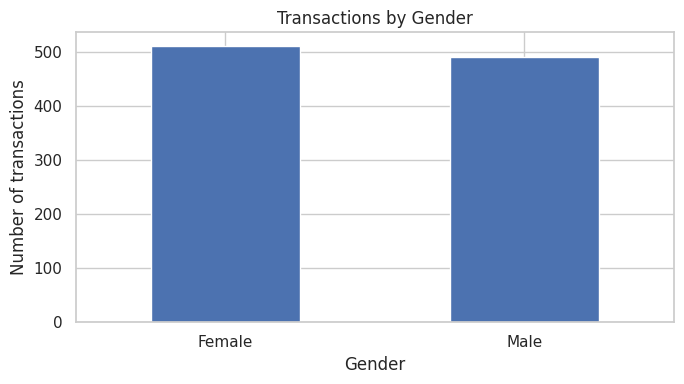

,Revenue by gender
Gender,
Female,232840
Male,223160


In [54]:
if "Age" in df.columns:
    bins = [0, 17, 24, 34, 44, 54, 64, np.inf]
    labels = ["Under 18", "18–24", "25–34", "35–44", "45–54", "55–64", "65+"]
    df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels, include_lowest=True)

    age_counts = df["Age Group"].value_counts().sort_index()
    age_counts.plot(kind="bar", figsize=(10, 5), title="Customer Transactions by Age Group")
    plt.xlabel("Age group")
    plt.ylabel("Number of transactions")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    if "Total Amount" in df.columns:
        age_revenue = df.groupby("Age Group", observed=False)["Total Amount"].sum()
        display(age_revenue.sort_values(ascending=False).to_frame("Revenue by age group"))

if "Gender" in df.columns:
    gender_counts = df["Gender"].value_counts()
    gender_counts.plot(kind="bar", figsize=(7, 4), title="Transactions by Gender")
    plt.xlabel("Gender")
    plt.ylabel("Number of transactions")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    if "Total Amount" in df.columns:
        gender_revenue = df.groupby("Gender")["Total Amount"].sum().sort_values(ascending=False)
        display(gender_revenue.to_frame("Revenue by gender"))
else:
    print("Age and/or Gender column is missing; check your dataset columns.")

**Observation prompt:** Identify the largest age group by transaction count and by revenue. Compare revenue by gender without assuming that a larger total necessarily means a higher average spend.

## 8. Product/category performance

No individual product-name column found. This dataset supports category-level analysis, not a reliable top-10 individual product ranking.


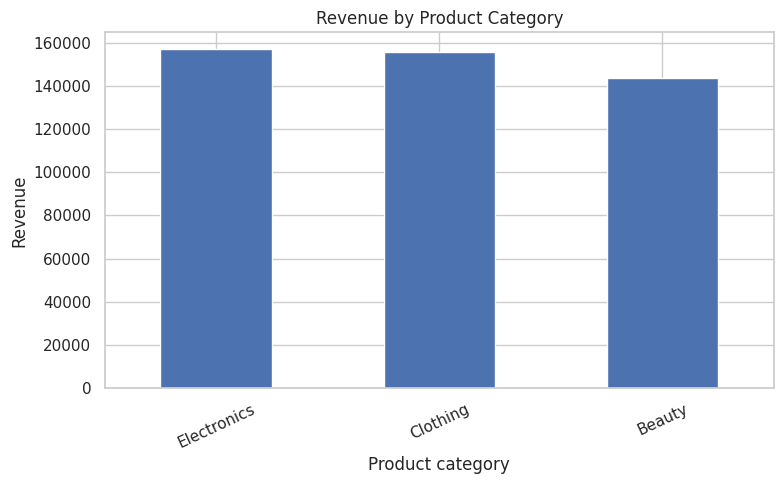

,Revenue
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


In [55]:
if "Total Amount" in df.columns:
    # If an individual product/name column exists, analyze it.
    product_col = next((c for c in ["Product", "Product Name", "Item", "Item Name"] if c in df.columns), None)

    if product_col:
        top_products = df.groupby(product_col)["Total Amount"].sum().sort_values(ascending=False).head(10)
        top_products.sort_values().plot(kind="barh", figsize=(10, 6), title="Top 10 Products by Revenue")
        plt.xlabel("Revenue")
        plt.ylabel("Product")
        plt.tight_layout()
        plt.show()
        display(top_products.to_frame("Revenue"))
    elif "Product Category" in df.columns:
        print("No individual product-name column found. This dataset supports category-level analysis, not a reliable top-10 individual product ranking.")
        category_revenue = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)
        category_revenue.plot(kind="bar", figsize=(8, 5), title="Revenue by Product Category")
        plt.xlabel("Product category")
        plt.ylabel("Revenue")
        plt.xticks(rotation=25)
        plt.tight_layout()
        plt.show()
        display(category_revenue.to_frame("Revenue"))
    else:
        print("No product or category column was found. Check the dataset schema.")
else:
    print("Total Amount column is missing.")

**Observation prompt:** Name the best-performing product or category based on the chart. If the dataset only contains broad categories, state that limitation clearly rather than inventing product-level results.

## 9. Correlation heatmap

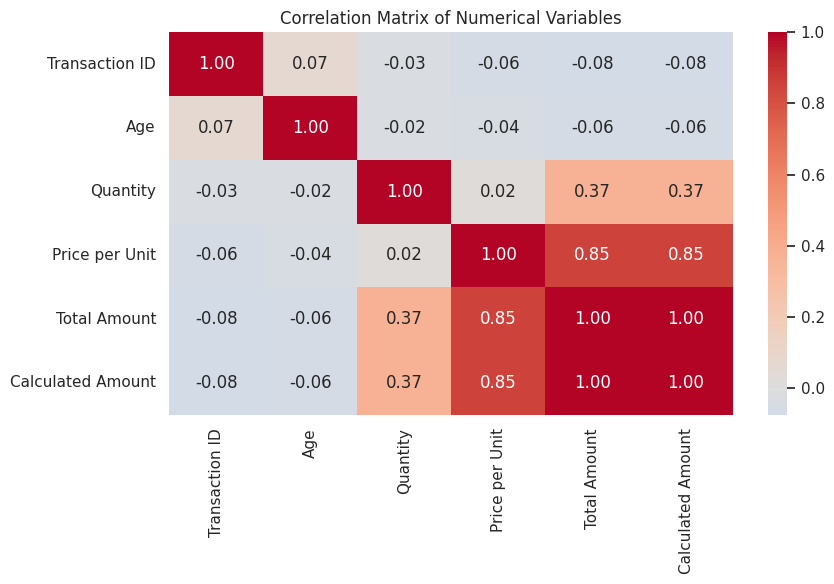

,Transaction ID,Age,Quantity,Price per Unit,Total Amount,Calculated Amount
Transaction ID,1.00,0.07,-0.03,-0.06,-0.08,-0.08
Age,0.07,1.00,-0.02,-0.04,-0.06,-0.06
Quantity,-0.03,-0.02,1.00,0.02,0.37,0.37
Price per Unit,-0.06,-0.04,0.02,1.00,0.85,0.85
Total Amount,-0.08,-0.06,0.37,0.85,1.00,1.00
Calculated Amount,-0.08,-0.06,0.37,0.85,1.00,1.00


In [56]:
corr_cols = df.select_dtypes(include=np.number).columns.tolist()
# Remove helper columns that duplicate information created for validation.
corr_cols = [c for c in corr_cols if c not in ["Amount Difference"]]

if len(corr_cols) >= 2:
    corr = df[corr_cols].corr(numeric_only=True)
    plt.figure(figsize=(9, 6))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
    plt.title("Correlation Matrix of Numerical Variables")
    plt.tight_layout()
    plt.show()
    display(corr)
else:
    print("At least two numeric columns are required for a correlation heatmap.")

**Observation prompt:** Describe the strongest relationships shown by the heatmap. Correlation indicates association, not proof that one variable causes another. If `Total Amount` is calculated from quantity and unit price, a strong correlation may be expected.

## 10. Additional visualization: order value distribution

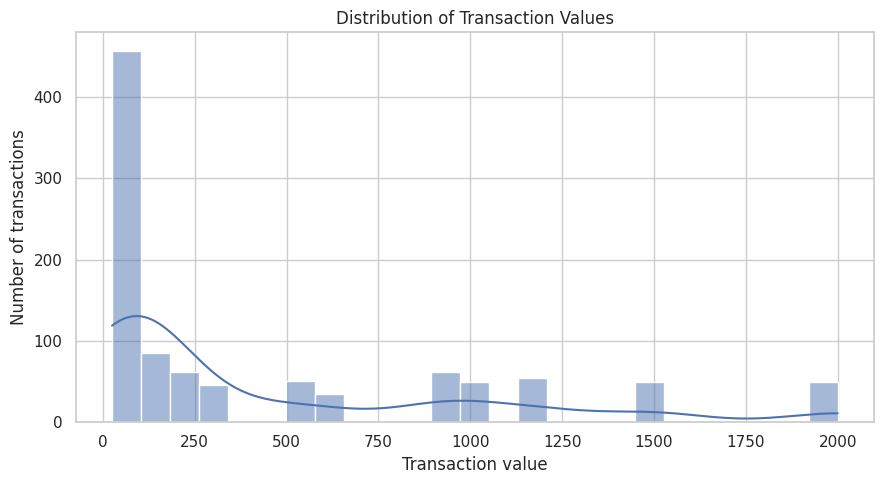

Average transaction value: 456.0
Median transaction value: 135.0


In [57]:
if "Total Amount" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df["Total Amount"].dropna(), bins=25, kde=True)
    plt.title("Distribution of Transaction Values")
    plt.xlabel("Transaction value")
    plt.ylabel("Number of transactions")
    plt.tight_layout()
    plt.show()

    print("Average transaction value:", round(df["Total Amount"].mean(), 2))
    print("Median transaction value:", round(df["Total Amount"].median(), 2))
else:
    print("Total Amount column is missing.")

**Observation prompt:** Compare the mean and median transaction values. If the mean is much higher than the median, a small number of high-value transactions may be pulling the average upward.

## 11. Key performance indicators

In [58]:
if "Total Amount" in df.columns:
    print(f"Total revenue: {df['Total Amount'].sum():,.2f}")
    print(f"Average transaction value: {df['Total Amount'].mean():,.2f}")
    print(f"Median transaction value: {df['Total Amount'].median():,.2f}")
    print(f"Number of records/transactions: {len(df):,}")

if "Customer ID" in df.columns:
    print(f"Unique customers: {df['Customer ID'].nunique():,}")

if "Quantity" in df.columns:
    print(f"Total units sold: {df['Quantity'].sum():,.0f}")

Total revenue: 456,000.00
Average transaction value: 456.00
Median transaction value: 135.00
Number of records/transactions: 1,000
Unique customers: 1,000
Total units sold: 2,514


## 12. Conclusion and actionable business recommendations

Complete this section after reviewing your actual outputs. Use your findings to fill in the brackets.

1. **Marketing by customer segment:** The age group with the highest revenue was **[insert group]**. Test a targeted campaign for this group and compare conversion rate and revenue against a control group.
2. **Product/category planning:** **[insert best-performing category/product]** generated the most revenue. Review its stock availability and evaluate complementary-product bundles; do not increase inventory without checking profit margin and stock turnover.
3. **Sales timing:** Revenue peaked in **[insert month/quarter]** and was lowest in **[insert month/quarter]**. Plan promotions and staffing around observed demand, then measure whether the plan improves sales.
4. **Transaction value:** The average transaction value was **[insert value]**, compared with a median of **[insert value]**. Test bundles or a minimum-spend offer if appropriate, and monitor profit as well as revenue.

### Limitations
- The findings describe this dataset and may not represent every retail business.
- Revenue is not the same as profit because costs and margins may be unavailable.
- If the file has only product categories and no product names, individual top-10 products cannot be identified from this dataset.
- Correlation does not establish causation.

## 13. Save a cleaned dataset (optional)

In [59]:
output_path = Path("../data/retail_sales_cleaned.csv")
try:
    output_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(output_path, index=False)
    print("Saved cleaned data to:", output_path)
except Exception as exc:
    print("Could not save to the repository data folder in this environment:", exc)

Saved cleaned data to: ../data/retail_sales_cleaned.csv
